#Antecedentes

Maximum Common Substructure similarity

mide qué tan parecidas son dos moléculas al encontrar la pieza estructural compartida más grande (subestructura), usando su tamaño para calcular una puntuación, lo que ayuda en el descubrimiento de fármacos y la comparación química, mostrando la superposición estructural mejor que solo las huellas dactilares y revelando partes funcionales comunes.

In [1]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 27.5 MB/s eta 0:00:00


In [2]:
#mport pandas as pd
#import numpy as np
#import seaborn as sn
#---------------------- RDKit packages
from rdkit.Chem import PandasTools
from rdkit import Chem
from rdkit.Chem import rdFMCS
from rdkit.Chem import AllChem
#from rdkit.Chem import rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Draw
from rdkit import DataStructs
#from rdkit.ML.Cluster import Butina
#------------------- progress bar
from tqdm import tqdm
#------------------- hide warning
import warnings
warnings.filterwarnings('ignore')

#Definimos las variables


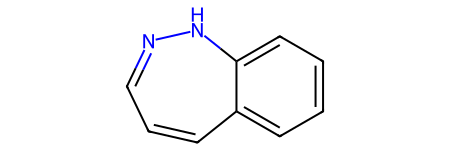

In [21]:
#farmacoforo
m= AllChem.MolFromSmiles("C1=CC=C2C(=C1)C=CC=NN2")
m

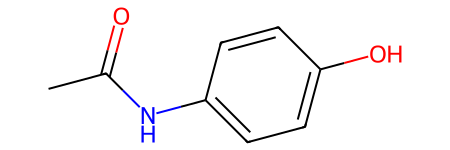

In [22]:
#molecula a comparar
a= AllChem.MolFromSmiles("CC(=O)NC1=CC=C(C=C1)O")
a

#IMAGEN COMPARATIVA

Vamos una función llamada find_mcs_and_draw que encontrará el MCS mediante la función rdFMCS.FindMCS([mol1, mol2]) y genera una imagen comparando las moléculas con el MCS resaltado

In [23]:
def find_mcs_and_draw(mol1, mol2):
    mcs = rdFMCS.FindMCS([mol1, mol2])
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString)
    if mcs_mol:
        # generacion de la imagen
        img = Draw.MolsToGridImage([mol1, mol2, mcs_mol],
                                    legends=['Molecule 1', 'Molecule 2', 'MCS'],
                                    highlightAtomLists=[
                                        mol1.GetSubstructMatch(mcs_mol),
                                        mol2.GetSubstructMatch(mcs_mol),
                                        [] # No highlighting for the MCS itself
                                    ])
        return img
    else:
        return None

In [24]:
comparison_image = find_mcs_and_draw(m, a)
if comparison_image:
    comparison_image
else:
    print("MCS not found. Cannot generate comparison image.")

Imprimimos Imagen

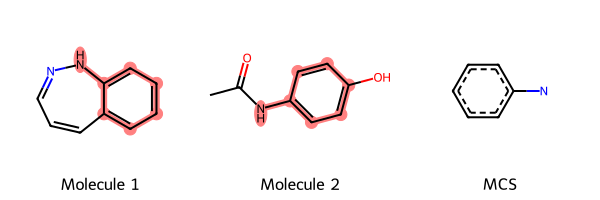

In [25]:
comparison_image

#find_mcs

In [8]:
def find_mcs(mol1_smiles, mol2_smiles):

    mol1 = Chem.MolFromSmiles(mol1_smiles)
    mol2 = Chem.MolFromSmiles(mol2_smiles)

    if mol1 is None or mol2 is None:
        print("Revisa el SMILES, el formato no es válido")
        return None, None, 0, False

    mcs = rdFMCS.FindMCS([mol1, mol2]) # esta es la función que ayuda a encontrar el MCS
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString)

    return mcs_mol, mcs.smartsString, mcs.numAtoms, True

#Ejercicio

Obtener el MCS entre morfina y heroina y entre cocaína y atropina

In [14]:
morfina = Chem.MolFromSmiles("O=C1[C@]2([C@]34C=5C(O2)=C(O)C=CC5C[C@]([C@@]3(C=C1)[H])(N(C)CC4)[H])[H]")
heroina = Chem.MolFromSmiles("CC(=O)O[C@H]1C=C[C@H]2[C@H]3CC4=C5[C@]2([C@H]1OC5=C(C=C4)OC(=O)C)CCN3C")

In [26]:
comparison_image_1 = find_mcs_and_draw(morfina, heroina)


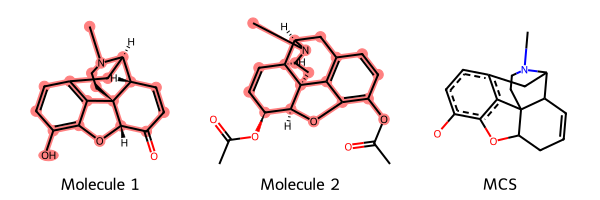

In [27]:
comparison_image_1

In [31]:
cocaina = Chem.MolFromSmiles("CN1[C@H]2CC[C@@H]1[C@H]([C@H](C2)OC(=O)C3=CC=CC=C3)C(=O)OC")
atropina = Chem.MolFromSmiles("CN1[C@H]2CC[C@@H]1C[C@@H](C2)OC(=O)C(CO)c3ccccc3")

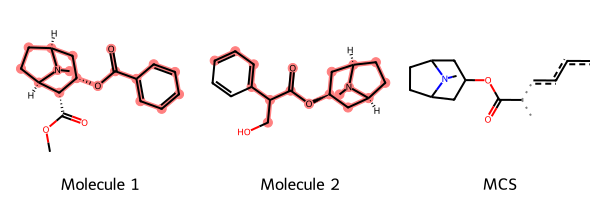

In [32]:
comparison_image_2 = find_mcs_and_draw(cocaina, atropina)
comparison_image_2

Ejemplo

In [9]:
# Example usage with your molecules
m_smiles = Chem.MolToSmiles(m)
a_smiles = Chem.MolToSmiles(a)

In [12]:
mcs_mol, mcs_smarts, mcs_atom_count, success = find_mcs(m_smiles, a_smiles)
if success:
    print("MCS found:")
    print("MCS SMILES:", Chem.MolToSmiles(mcs_mol))
    print("SMARTS:", mcs_smarts)
    print("Number of atoms:", mcs_atom_count)
else:
    print("MCS not found.")

MCS found:
MCS SMILES: NC1:C:C:C:C:C:1
SMARTS: [#7]-[#6]1:[#6]:[#6]:[#6]:[#6]:[#6]:1
Number of atoms: 7


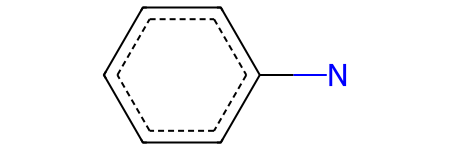

In [13]:
MCS = AllChem.MolFromSmarts("[#7]-[#6]1:[#6]:[#6]:[#6]:[#6]:[#6]:1")
MCS

Creado por Maricarmen Cedillo y revisado por el Dr. Erick Correa
FES Zaragoza UNAM